In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import json
import sys
from pathlib import Path

project_root = Path("../../..").resolve()
sys.path.append(str(project_root))

import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RandomizedSearchCV, train_test_split

from utils import DataManager, exclude_column
from utils.plotter import actual_vs_prediction, feature_importance, y_fdistro


In [3]:
COLUMNS = "bioactivity_columns.json"

In [19]:
df = DataManager(path='bioactivity/her2').dataset 

with open(COLUMNS, 'r') as f:
    data = json.load(f)

df = df[data['columns']]
len(df.columns)

1041

In [6]:
fp_cols = [col for col in df.columns if col.startswith('fp_')]
unique_cols = df[fp_cols].nunique()
constant_cols = unique_cols[unique_cols == 1]

# exclude_column(COLUMNS, col_name="her2_exclusion", col=list(constant_cols.index))
df = df.drop(columns=constant_cols.index)
len(df.columns)

1036

In [7]:
null = (df.isnull()).sum().sum()
null

np.int64(0)

In [8]:
X = df.drop(columns='pIC50')
y = df['pIC50']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=25)
len(X_test)

450

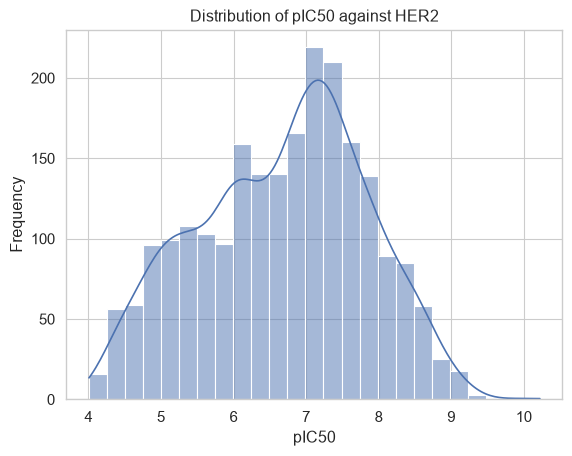

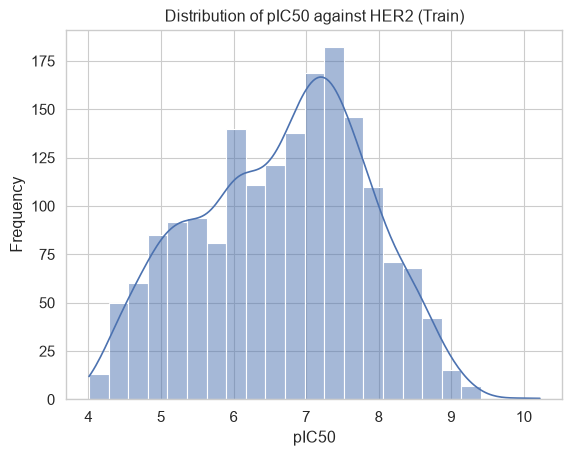

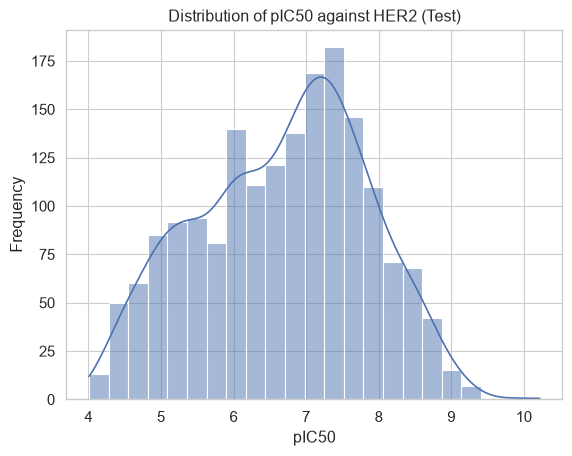

In [13]:
y_fdistro(y, "pIC50 against HER2")
y_fdistro(y_train, "pIC50 against HER2 (Train)")
y_fdistro(y_train, "pIC50 against HER2 (Test)")


In [24]:
model = RandomForestRegressor(
    random_state=25,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [500, 1000, 1500],
    "max_depth": [None, 5, 10, 20, 30, 50],
    "min_samples_split": [2, 5, 10, 15],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", "log2", 0.2, 0.5, 0.8, 1.0],
    "max_samples": [None, 0.6, 0.8, 1.0]
}

search = RandomizedSearchCV(
    model,
    param_distributions=param_grid,
    n_iter=50,
    scoring="neg_root_mean_squared_error",
    cv=5,
    random_state=42,
    n_jobs=-1
)

search.fit(X_train, y_train)
print(search.best_params_)
print(search.best_score_)


{'n_estimators': 1000, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_samples': None, 'max_features': 0.8, 'max_depth': None}
-0.6570873474447962


In [9]:
best_model = RandomForestRegressor(
    n_estimators=1000,
    min_samples_split=2,
    min_samples_leaf=1, 
    max_samples=None,
    max_features=0.8,
    max_depth=None
)
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)

In [10]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'RMSE: {rmse}')
print(f'MSE: {mse}')
print(f'MAE: {mae}')
print(f'R2: {r2}')


RMSE: 0.5848497244576233
MSE: 0.3420492001981579
MAE: 0.43741545135436505
R2: 0.7286709357445164


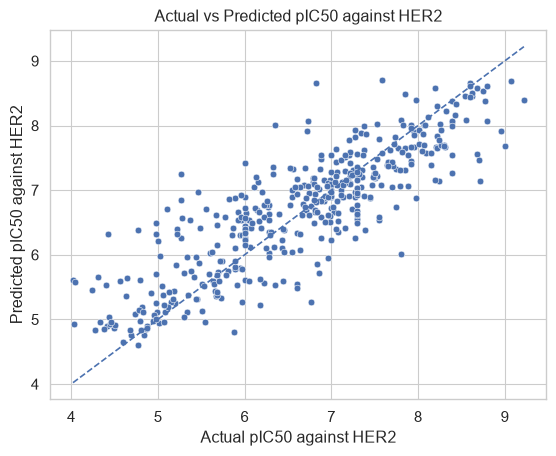

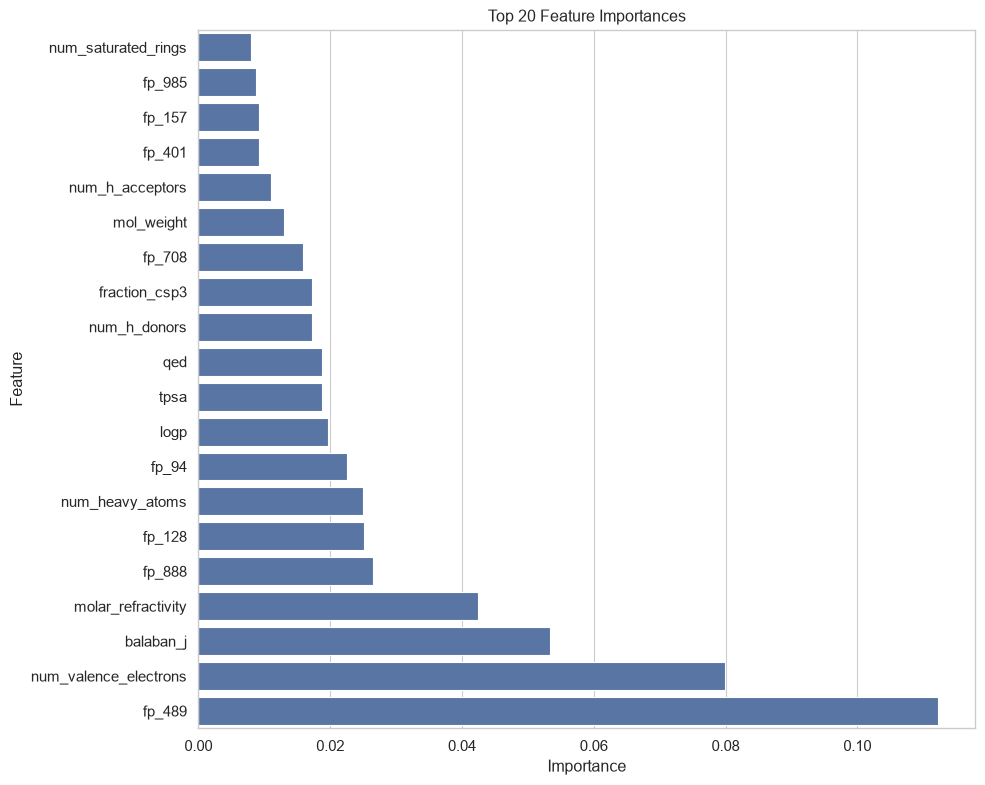

,Feature,Importance
13,num_saturated_rings,0.007902
996,fp_985,0.008795
170,fp_157,0.009176
413,fp_401,0.009258
4,num_h_acceptors,0.011043
0,mol_weight,0.012925
719,fp_708,0.015859
9,fraction_csp3,0.017234
3,num_h_donors,0.017238
15,qed,0.018717


In [18]:
actual_vs_prediction(y_test, y_pred, name="pIC50 against HER2")
feature_importance(best_model, X_train.columns)